In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import periodogram

# ============================================================
# SETTINGS
# ============================================================

CSV_FILE = "C:\\Users\\user\\OneDrive\\Desktop\\Msc thesis\\di_matteo_data\\Bangkok_SET.csv"      # change this
PRICE_COLUMN = "Close"           # or "close"
MAX_TAU = 19                     # same as paper

# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(CSV_FILE)

price = df[PRICE_COLUMN].values

# log returns (paper uses returns for stocks and FX)
returns = np.diff(np.log(price))

# ============================================================
# GENERALIZED HURST EXPONENT
# ============================================================

taus = np.arange(1, MAX_TAU + 1)

K2 = []

for tau in taus:

    increments = returns[tau:] - returns[:-tau]

    numerator = np.mean(np.abs(increments) ** 2)

    denominator = np.mean(np.abs(returns[:-tau]) ** 2)

    K2.append(numerator / denominator)

K2 = np.array(K2)

# fit

coef = np.polyfit(np.log10(taus), np.log10(K2), 1)

slope = coef[0]

H2 = slope / 2

print(f"H(2) = {H2:.4f}")

# ============================================================
# POWER SPECTRUM
# ============================================================

freq, psd = periodogram(
    returns,
    detrend='linear',
    scaling='density'
)

mask = freq > 0

freq = freq[mask]
psd = psd[mask]

# ============================================================
# THEORETICAL LINE
# ============================================================

beta = 2 * H2 + 1

theory = freq ** (-beta)

# vertically align

scale = psd[5] / theory[5]

theory *= scale

print(f"Predicted beta = {beta:.3f}")

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(8,6))

plt.loglog(freq, psd,
           color='black',
           lw=1.6,
           label='Power spectrum')

plt.loglog(freq,
           theory,
           '--',
           color='red',
           lw=2,
           label=rf'$f^{{-(2H(2)+1)}}$')

plt.xlabel("Frequency (1/day)", fontsize=12)
plt.ylabel("S(f)", fontsize=12)

plt.title("Power Spectrum vs Generalized Hurst Prediction")

plt.legend()

plt.grid(True, which="both", alpha=.3)

plt.tight_layout()

plt.show()

TypeError: loop of ufunc does not support argument 0 of type str which has no callable log method

In [5]:
df = pd.read_csv(CSV_FILE)

In [6]:
print(df.head())

print(df.columns)

print(df.dtypes)

        Price              Close               High                Low  \
0      Ticker            ^SET.BK            ^SET.BK            ^SET.BK   
1        Date                NaN                NaN                NaN   
2  1997-01-02  803.1300048828125  828.5499877929688  799.4199829101562   
3  1997-01-03   787.469970703125  798.0599975585938   776.739990234375   
4  1997-01-06    790.22998046875    790.22998046875   779.530029296875   

                Open   Volume  
0            ^SET.BK  ^SET.BK  
1                NaN      NaN  
2  828.5499877929688    50500  
3  798.0599975585938    63200  
4  787.3499755859375    54700  
Index(['Price', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')
Price     object
Close     object
High      object
Low       object
Open      object
Volume    object
dtype: object


In [7]:
import pandas as pd
import numpy as np

CSV_FILE = "di_matteo_data/Bangkok_SET.csv"
PRICE_COLUMN = "Close"

df = pd.read_csv(CSV_FILE)

# Remove yfinance extra rows: Ticker row + Date row
df = df[~df["Price"].isin(["Ticker", "Date"])].copy()

# Rename Price column to Date
df = df.rename(columns={"Price": "Date"})

# Convert date and numeric columns
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in ["Close", "High", "Low", "Open", "Volume"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Date", PRICE_COLUMN])
df = df.sort_values("Date").reset_index(drop=True)

price = df[PRICE_COLUMN].values.astype(float)

# Log returns
returns = np.diff(np.log(price))

print(df.head())
print(df.dtypes)
print("Number of prices:", len(price))
print("Number of returns:", len(returns))

        Date       Close        High         Low        Open  Volume
0 1997-01-02  803.130005  828.549988  799.419983  828.549988   50500
1 1997-01-03  787.469971  798.059998  776.739990  798.059998   63200
2 1997-01-06  790.229980  790.229980  779.530029  787.349976   54700
3 1997-01-07  820.109985  820.109985  791.830017  791.830017  104400
4 1997-01-08  831.929993  848.950012  824.280029  825.049988  151700
Date      datetime64[ns]
Close            float64
High             float64
Low              float64
Open             float64
Volume             int64
dtype: object
Number of prices: 1228
Number of returns: 1227


H(2) = 0.5763
beta = 2H(2)+1 = 2.1525


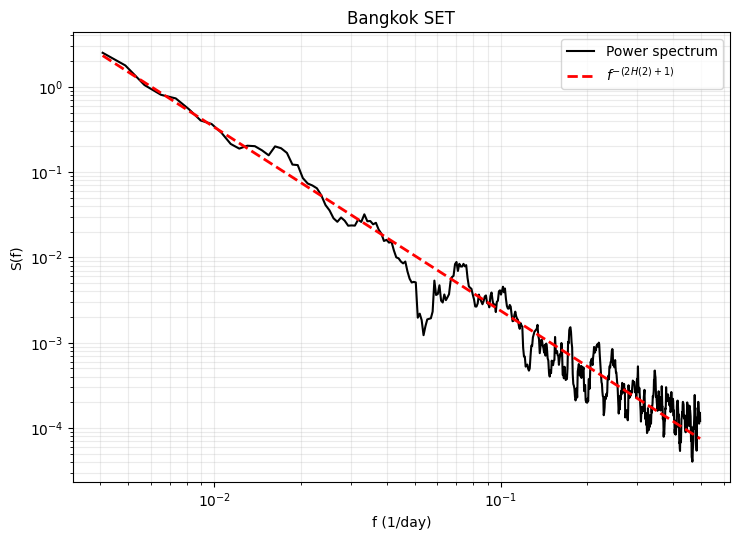

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import periodogram

CSV_FILE = "C:\\Users\\user\\OneDrive\\Desktop\\Msc thesis\\di_matteo_data\\Bangkok_SET.csv"
ASSET_NAME = "Bangkok SET"
PRICE_COLUMN = "Close"

MAX_TAU = 19

# ----------------------------
# Load + clean yfinance CSV
# ----------------------------
df = pd.read_csv(CSV_FILE)

if "Price" in df.columns:
    df = df[~df["Price"].isin(["Ticker", "Date"])].copy()
    df = df.rename(columns={"Price": "Date"})

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Date", PRICE_COLUMN])
df = df.sort_values("Date").reset_index(drop=True)

price = df[PRICE_COLUMN].to_numpy(dtype=float)
X = np.log(price)

# ----------------------------
# Generalized Hurst H(2)
# ----------------------------
q = 2
taus = np.arange(1, MAX_TAU + 1)

Kq = []

for tau in taus:
    inc = np.abs(X[tau:] - X[:-tau]) ** q
    Kq.append(np.mean(inc) / np.mean(np.abs(X[:-tau]) ** q))

Kq = np.array(Kq)

slope, _ = np.polyfit(np.log10(taus), np.log10(Kq), 1)

H2 = slope / q
beta = 2 * H2 + 1

print(f"H(2) = {H2:.4f}")
print(f"beta = 2H(2)+1 = {beta:.4f}")

# ----------------------------
# PSD of LOG-PRICE, not returns
# ----------------------------
freq, psd = periodogram(
    X - np.mean(X),
    fs=1.0,
    detrend="linear",
    scaling="density"
)

mask = (freq > 0) & (psd > 0)
freq = freq[mask]
psd = psd[mask]

# Keep region similar to paper
mask = (freq >= 1e-4) & (freq <= 1)
freq = freq[mask]
psd = psd[mask]

# ----------------------------
# Smooth PSD using moving average in log space
# ----------------------------
log_f = np.log10(freq)
log_psd = np.log10(psd)

window = 9
kernel = np.ones(window) / window

log_psd_smooth = np.convolve(log_psd, kernel, mode="same")

# Remove edge artifacts
edge = window // 2
freq_s = freq[edge:-edge]
psd_s = 10 ** log_psd_smooth[edge:-edge]

# ----------------------------
# Theoretical line with fixed slope
# ----------------------------
log_f_s = np.log10(freq_s)
log_psd_s = np.log10(psd_s)

intercept = np.mean(log_psd_s + beta * log_f_s)
theory = 10 ** intercept * freq_s ** (-beta)

# ----------------------------
# Plot
# ----------------------------
plt.figure(figsize=(7.5, 5.5))

plt.loglog(freq_s, psd_s, color="black", lw=1.5, label="Power spectrum")

plt.loglog(
    freq_s,
    theory,
    "r--",
    lw=2,
    label=rf"$f^{{-(2H(2)+1)}}$"
)

plt.xlabel("f (1/day)")
plt.ylabel("S(f)")
plt.title(ASSET_NAME)

plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

H(2) = 0.4513
beta = 2H(2)+1 = 1.9026


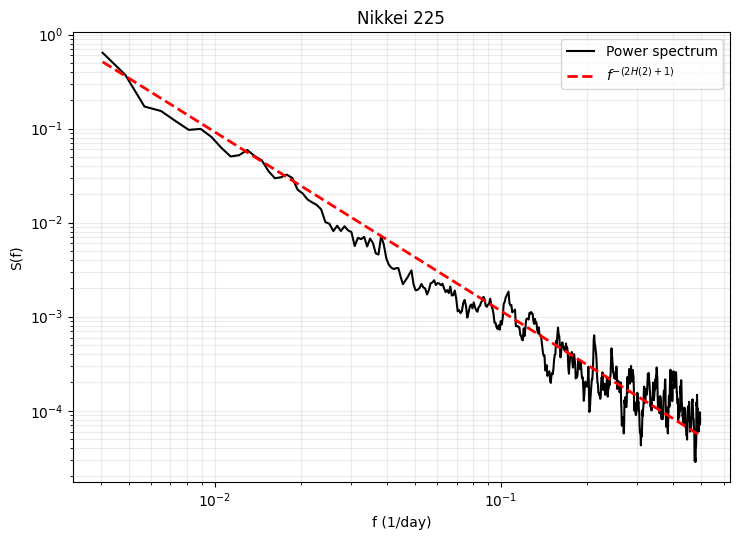

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import periodogram

CSV_FILE = "C:\\Users\\user\\OneDrive\\Desktop\\Msc thesis\\di_matteo_data\\Nikkei225.csv"
ASSET_NAME = "Nikkei 225"
PRICE_COLUMN = "Close"

MAX_TAU = 19

# ----------------------------
# Load + clean yfinance CSV
# ----------------------------
df = pd.read_csv(CSV_FILE)

if "Price" in df.columns:
    df = df[~df["Price"].isin(["Ticker", "Date"])].copy()
    df = df.rename(columns={"Price": "Date"})

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Date", PRICE_COLUMN])
df = df.sort_values("Date").reset_index(drop=True)

price = df[PRICE_COLUMN].to_numpy(dtype=float)
X = np.log(price)

# ----------------------------
# Generalized Hurst H(2)
# ----------------------------
q = 2
taus = np.arange(1, MAX_TAU + 1)

Kq = []

for tau in taus:
    inc = np.abs(X[tau:] - X[:-tau]) ** q
    Kq.append(np.mean(inc) / np.mean(np.abs(X[:-tau]) ** q))

Kq = np.array(Kq)

slope, _ = np.polyfit(np.log10(taus), np.log10(Kq), 1)

H2 = slope / q
beta = 2 * H2 + 1

print(f"H(2) = {H2:.4f}")
print(f"beta = 2H(2)+1 = {beta:.4f}")

# ----------------------------
# PSD of LOG-PRICE, not returns
# ----------------------------
freq, psd = periodogram(
    X - np.mean(X),
    fs=1.0,
    detrend="linear",
    scaling="density"
)

mask = (freq > 0) & (psd > 0)
freq = freq[mask]
psd = psd[mask]

# Keep region similar to paper
mask = (freq >= 1e-4) & (freq <= 1)
freq = freq[mask]
psd = psd[mask]

# ----------------------------
# Smooth PSD using moving average in log space
# ----------------------------
log_f = np.log10(freq)
log_psd = np.log10(psd)

window = 9
kernel = np.ones(window) / window

log_psd_smooth = np.convolve(log_psd, kernel, mode="same")

# Remove edge artifacts
edge = window // 2
freq_s = freq[edge:-edge]
psd_s = 10 ** log_psd_smooth[edge:-edge]

# ----------------------------
# Theoretical line with fixed slope
# ----------------------------
log_f_s = np.log10(freq_s)
log_psd_s = np.log10(psd_s)

intercept = np.mean(log_psd_s + beta * log_f_s)
theory = 10 ** intercept * freq_s ** (-beta)

# ----------------------------
# Plot
# ----------------------------
plt.figure(figsize=(7.5, 5.5))

plt.loglog(freq_s, psd_s, color="black", lw=1.5, label="Power spectrum")

plt.loglog(
    freq_s,
    theory,
    "r--",
    lw=2,
    label=rf"$f^{{-(2H(2)+1)}}$"
)

plt.xlabel("f (1/day)")
plt.ylabel("S(f)")
plt.title(ASSET_NAME)

plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()